# 00｜先知道自己手里有什么

本课程从一个问题开始：**一张表存在，是否等于它能支撑研究？**

运行前先执行 README 的准备命令。所有单元格只读取本机固定快照，不发网络请求，不写 QuestDB。先看本书，再按 01→02→03→04→05→06→07→08 的顺序。

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/research-playbook.properties").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from tools.research_playbook.data import load_frame, inventory, data_root, sha
from tools.research_playbook.analysis import plot_style
plot_style()
pd.set_option("display.max_columns", 12)

## 1. 把“能读”与“能证明”分开

`ready` 只表示本教材中注明的用途可用。BTC 日线准入了 OHLC，不代表成交量冲突已经解决；宏观数据能做描述图，不代表历史时点可回测。`blocked` 会直接列出缺什么，不用零值或假数据填空。

In [2]:
inv = inventory()
display(inv[["dataset", "status", "rows", "scope", "reason"]].fillna("—"))

,dataset,status,rows,scope,reason
0,macro,ready,10504.0,最新修订观测值；非历史发布时间/vintage；不可直接做时点回测,—
1,macro_context,ready,8630.0,通胀、就业、利率、货币、信用和美元的修订后描述序列；不支持历史可见性回测,—
2,onchain,ready,8114.0,Coin Metrics社区回溯；费用为原生币、价格为USD参考价；空值保留。CC BY-N...,—
3,ml4t_sp500,ready,635703.0,ML4T固定commit的AlgoSeek 2017—2021教学日线；独立参考面板，非本项...,—
4,stablecoins,ready,3264.0,DefiLlama当前回溯的流通市值；不是支付额、桥接流量或历史可见快照,—
5,ai_annual,ready,12.0,四家公司2022—2024财政年度；官方年报人工核对；非季度、非完整AI收入,—
6,ai_quarterly,blocked,—,—,SEC companyfacts下载返回403；尚无四公司季度及修订可见性验收。年度种子表可...
7,btc_daily,ready,2488.0,既有固定批次，严格按所选字段准入；日线仅OHLC，资金费仅实际结算事件；无历史PIT,—
8,btc_funding,ready,7464.0,既有固定批次，严格按所选字段准入；日线仅OHLC，资金费仅实际结算事件；无历史PIT,—
9,historical_results,ready,14.0,2026-10-30已提交验收摘要；不是本次重新执行ETF/ETH回放,—


## 2. 容量花在哪里

预算是整个研究数据目录 **300,000,000 字节**，含原件、派生文件、回执和复制的质量证据。下载器单文件上限 25 MB；Python 写入前还计入临时副本峰值。虚拟环境属于软件依赖，单独记录体积，不藏在数据预算里。

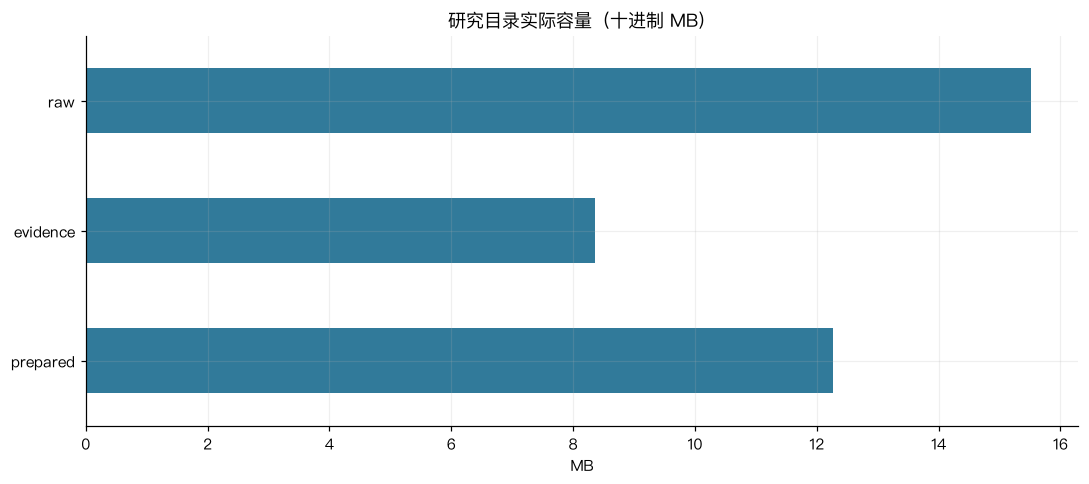

数据合计 36.15 MB / 300 MB


In [3]:
from tools.research_playbook.data import size_bytes
root = data_root()
sizes = pd.Series({p.name: size_bytes(p) / 1e6 for p in root.iterdir() if p.is_dir()})
ax=sizes.plot.barh(color="#317a9a", title="研究目录实际容量（十进制 MB）")
ax.set_xlabel("MB"); plt.tight_layout(); plt.show()
print(f"数据合计 {size_bytes(root)/1e6:.2f} MB / 300 MB")

**读图：** 原件使数字可以追溯，派生表让代码易读，证据文件解释为什么允许或拒绝某种用途。即使某个分组较大，也不能在没核对引用前删掉它。压缩文件小，不代表展开后的内存也小。

## 3. 做一次真的日线完整性检查

BTC 按 UTC 连续自然日。美股必须用交易日历，不能照抄这段。我们比较日期集合，同时检查重复和 OHLC 边界；只比较行数或最大日期会漏掉中间断点。

In [4]:
btc=load_frame("btc_daily")
t=pd.DatetimeIndex(btc.open_time).as_unit("ns")
expected=pd.date_range(t.min(),t.max(),freq="D")
check={"实际行数":len(btc),"重复日期":int(t.duplicated().sum()),"缺日":len(expected.difference(t)),"额外日期":len(t.difference(expected)),"非正价格":int((btc[["open","high","low","close"]]<=0).any(axis=1).sum()),"首日":str(t.min().date()),"末日":str(t.max().date())}
display(pd.Series(check))
assert check["重复日期"]==check["缺日"]==check["额外日期"]==0

实际行数          2488
重复日期             0
缺日               0
额外日期             0
非正价格             0
首日      2020-01-01
末日      2026-10-23
dtype: object

## 4. 每次研究要写下的六件事

1. 问题：例如“200 日趋势能否减少 BTC 回撤”。
2. 范围：BTCUSDT、Binance、现货、日线、UTC。
3. 时间：观察日、收盘时刻、来源可用时刻、取得时刻分别是什么。
4. 口径：USDT 不是 USD；现金资本开支不是含租赁资本开支。
5. 基线：同窗口买入持有，不能拿不同起点比较。
6. 反证：加费用后失效、换时期失效、缺口无法解释，都应允许得出“目前证据不足”。

**练习：** 把宏观 `retrieved_at` 当成历史公布时刻会产生什么问题？答：下载日期只证明这次看到了该值，无法证明十年前已经知道同样的修订值。